In [4]:
import os
print(os.getcwd())


c:\Users\user\AppData\Local\Programs\Microsoft VS Code


In [45]:
os.chdir("C:\\Users\\user\\OneDrive\\Documents\\DSA1080A")

In [46]:
#Loading the dataset
import pandas as pd
df=pd.read_csv("cleaned_data.csv")

In [47]:
df.head()


,utc_timestamp,GB_GBN_load_actual_entsoe_transparency,GB_GBN_load_forecast_entsoe_transparency,GB_GBN_price_day_ahead,GB_GBN_solar_capacity,GB_GBN_solar_generation_actual,GB_GBN_solar_profile,GB_GBN_wind_capacity,GB_GBN_wind_generation_actual,GB_GBN_wind_profile,GB_GBN_wind_offshore_capacity,GB_GBN_wind_offshore_generation_actual,GB_GBN_wind_offshore_profile,GB_GBN_wind_onshore_capacity,GB_GBN_wind_onshore_generation_actual,GB_GBN_wind_onshore_profile
0,2014-12-31 23:00:00+00:00,NaN,NaN,NaN,2664.0,NaN,NaN,11554.0,NaN,NaN,4040.0,NaN,NaN,7514.0,NaN,NaN
1,2015-01-01 00:00:00+00:00,26758.0,32057.0,NaN,2669.0,NaN,NaN,11555.0,NaN,NaN,4040.0,NaN,NaN,7516.0,NaN,NaN
2,2015-01-01 01:00:00+00:00,27166.0,31738.0,NaN,2669.0,NaN,NaN,11555.0,782.0,0.0676,4040.0,117.0,0.0290,7516.0,664.0,0.0884
3,2015-01-01 02:00:00+00:00,24472.0,30690.0,NaN,2669.0,NaN,NaN,11555.0,785.0,0.0680,4040.0,120.0,0.0296,7516.0,666.0,0.0886
4,2015-01-01 03:00:00+00:00,23003.0,28442.0,NaN,2669.0,NaN,NaN,11555.0,776.0,0.0672,4040.0,115.0,0.0284,7516.0,662.0,0.0880


In [48]:
df.columns


Index(['utc_timestamp', 'GB_GBN_load_actual_entsoe_transparency',
       'GB_GBN_load_forecast_entsoe_transparency', 'GB_GBN_price_day_ahead',
       'GB_GBN_solar_capacity', 'GB_GBN_solar_generation_actual',
       'GB_GBN_solar_profile', 'GB_GBN_wind_capacity',
       'GB_GBN_wind_generation_actual', 'GB_GBN_wind_profile',
       'GB_GBN_wind_offshore_capacity',
       'GB_GBN_wind_offshore_generation_actual',
       'GB_GBN_wind_offshore_profile', 'GB_GBN_wind_onshore_capacity',
       'GB_GBN_wind_onshore_generation_actual', 'GB_GBN_wind_onshore_profile'],
      dtype='object')

In [49]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50401 entries, 0 to 50400
Data columns (total 16 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   utc_timestamp                             50401 non-null  object 
 1   GB_GBN_load_actual_entsoe_transparency    50394 non-null  float64
 2   GB_GBN_load_forecast_entsoe_transparency  50280 non-null  float64
 3   GB_GBN_price_day_ahead                    50290 non-null  float64
 4   GB_GBN_solar_capacity                     43801 non-null  float64
 5   GB_GBN_solar_generation_actual            50346 non-null  float64
 6   GB_GBN_solar_profile                      43752 non-null  float64
 7   GB_GBN_wind_capacity                      43801 non-null  float64
 8   GB_GBN_wind_generation_actual             50360 non-null  float64
 9   GB_GBN_wind_profile                       43760 non-null  float64
 10  GB_GBN_wind_offshore_capacity     

In [50]:
demand_column="GB_GBN_load_actual_entsoe_transparency"
demand = pd.to_numeric(df[demand_column], errors="coerce").dropna()

In [51]:
print("Number of observations:", demand.count())
print("Mean:", demand.mean())
print("Median:", demand.median())
print("Minimum:", demand.min())
print("Maximum:", demand.max())
print("Range:",demand.max()-demand.min())
print("Standard deviation:", demand.std())
print("Skewness:", demand.skew())

Number of observations: 50394
Mean: 34920.87415168472
Median: 35306.5
Minimum: 511.0
Maximum: 57388.0
Range: 56877.0
Standard deviation: 7888.618203067516
Skewness: -0.0612279562991516


<function matplotlib.pyplot.show(close=None, block=None)>

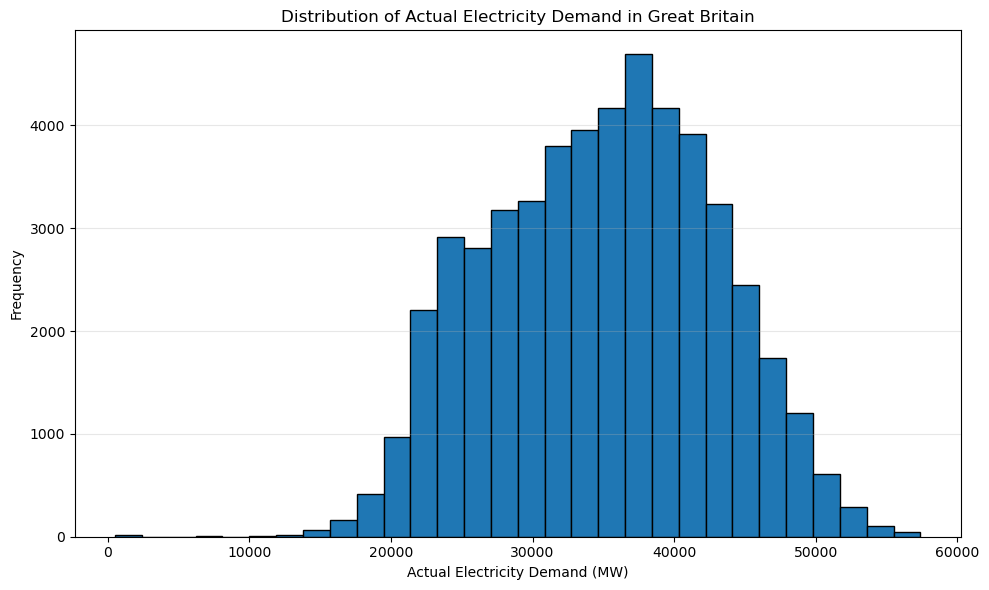

In [52]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
plt.hist(demand, bins=30, edgecolor="black")
plt.title("Distribution of Actual Electricity Demand in Great Britain")
plt.xlabel("Actual Electricity Demand (MW)")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show

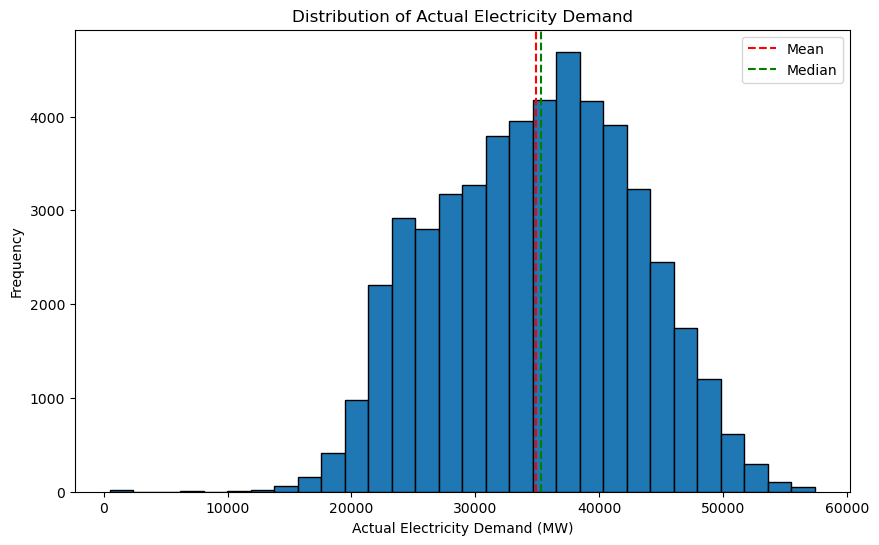

In [53]:
plt.figure(figsize=(10, 6))

plt.hist(demand, bins=30, edgecolor="black")

plt.axvline(demand.mean(), color="red",
            linestyle="--", label="Mean")

plt.axvline(demand.median(), color="green",
            linestyle="--", label="Median")

plt.title("Distribution of Actual Electricity Demand")
plt.xlabel("Actual Electricity Demand (MW)")
plt.ylabel("Frequency")

plt.legend()
plt.show()

In [54]:
import numpy as np
counts, bin_edges = np.histogram(demand,bins=30)

In [55]:
for i in range(len(counts)):
    print(
        f"{bin_edges[i]:,.0f} – "
        f"{bin_edges[i+1]:,.0f} MW: "
        f"{counts[i]:,} observations"
    )

511 – 2,407 MW: 20 observations
2,407 – 4,303 MW: 2 observations
4,303 – 6,199 MW: 1 observations
6,199 – 8,095 MW: 3 observations
8,095 – 9,990 MW: 1 observations
9,990 – 11,886 MW: 4 observations
11,886 – 13,782 MW: 16 observations
13,782 – 15,678 MW: 61 observations
15,678 – 17,574 MW: 158 observations
17,574 – 19,470 MW: 412 observations
19,470 – 21,366 MW: 974 observations
21,366 – 23,262 MW: 2,205 observations
23,262 – 25,158 MW: 2,914 observations
25,158 – 27,054 MW: 2,805 observations
27,054 – 28,950 MW: 3,174 observations
28,950 – 30,845 MW: 3,266 observations
30,845 – 32,741 MW: 3,797 observations
32,741 – 34,637 MW: 3,956 observations
34,637 – 36,533 MW: 4,171 observations
36,533 – 38,429 MW: 4,691 observations
38,429 – 40,325 MW: 4,170 observations
40,325 – 42,221 MW: 3,915 observations
42,221 – 44,117 MW: 3,232 observations
44,117 – 46,013 MW: 2,445 observations
46,013 – 47,908 MW: 1,743 observations
47,908 – 49,804 MW: 1,203 observations
49,804 – 51,700 MW: 613 observatio

In [56]:
highest_bin = counts.argmax()

print("Highest frequency:", counts[highest_bin])

print(
    "Demand interval:",
    bin_edges[highest_bin],
    "to",
    bin_edges[highest_bin + 1],
    "MW"
)

Highest frequency: 4691
Demand interval: 36533.1 to 38429.0 MW


In [57]:
percentage = ((counts[highest_bin])/ len(demand)) * 100
print("Percentage:", percentage, "%")

Percentage: 9.308647854903361 %
